## Imports - config

In [28]:
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix
)

from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings(
    "ignore",
    message="X does not have valid feature names, but LGBMClassifier was fitted with feature names"
)

RANDOM_SEED = 42

DROP_CLASSES = True
DROP_WEAK_LINKS = {
    "RightHeelRises",
}
DROP_TIES = False

# Rare merge inside experts
MERGE_RARE = True
MIN_COUNT_PER_CLASS = 10
RARE_SUFFIX = "__RARE"

SCORES_PATH = "../../data/processed/20190108_scores_and_weak_links.csv"
FEATURES_PATH = "../../data/processed/AimoScore_WeakLink_big_scores.csv"


## Load data

In [29]:
scores = pd.read_csv(SCORES_PATH)
big = pd.read_csv(FEATURES_PATH)

NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

if DROP_CLASSES:
    indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]

scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
ties = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)
scores["HasTie"] = ties

scores_labeled = scores.loc[~scores["HasTie"]].copy() if DROP_TIES else scores.copy()
scores_labeled = scores_labeled.dropna(subset=["WeakestLink"])

print("Unique WeakestLink classes:", scores_labeled["WeakestLink"].nunique())
display(scores_labeled["WeakestLink"].value_counts())


Unique WeakestLink classes: 13


WeakestLink
LeftArmFallForward              630
RightArmFallForward             472
RightKneeMovesOutward           278
RightShoulderElevation          250
ForwardHead                     117
ExcessiveForwardLean            100
LeftAsymmetricalWeightShift      73
LeftShoulderElevation            58
LeftKneeMovesOutward             49
RightKneeMovesInward             45
RightAsymmetricalWeightShift     19
LeftKneeMovesInward               3
LeftHeelRises                     2
Name: count, dtype: int64

## Merge features + build X/y/ids

In [30]:
labels = scores_labeled[["ID", "WeakestLink"]]
data = big.merge(labels, on="ID", how="inner")

angle_cols = [c for c in data.columns if c.startswith("No_") and c.endswith("_Angle_Deviation")]
nasm_cols  = [c for c in data.columns if c.startswith("No_") and c.endswith("_NASM_Deviation")]
feature_cols = sorted(angle_cols) + sorted(nasm_cols)

X = data[feature_cols].apply(pd.to_numeric, errors="coerce")
y = data["WeakestLink"].astype(str)
ids = data["ID"]

mask = X.notna().all(axis=1)

X = X.loc[mask].reset_index(drop=True)
y = y.loc[mask].reset_index(drop=True)
ids = ids.loc[mask].reset_index(drop=True)

print("X shape:", X.shape)
print("Min class count:", int(y.value_counts().min()))


X shape: (2094, 38)
Min class count: 2


## Define regions

In [31]:
UPPER = {
    "ForwardHead",
    "LeftArmFallForward",
    "RightArmFallForward",
    "LeftShoulderElevation",
    "RightShoulderElevation",
}

LOWER = {
    "LeftKneeMovesInward",
    "RightKneeMovesInward",
    "LeftKneeMovesOutward",
    "RightKneeMovesOutward",
    "LeftHeelRises",
}

OTHER = {
    "ExcessiveForwardLean",
    "LeftAsymmetricalWeightShift",
    "RightAsymmetricalWeightShift",
}

def to_region(lbl: str) -> str:
    if lbl in UPPER: return "Upper"
    if lbl in LOWER: return "Lower"
    if lbl in OTHER: return "Other"
    return "Other"

region = y.map(to_region)
print(region.value_counts())


WeakestLink
Upper    1526
Lower     376
Other     192
Name: count, dtype: int64


## Train/test split

In [32]:
unique_ids = ids.unique()
unique_regions = pd.Series(region.values, index=ids).groupby(level=0).first().loc[unique_ids]

train_ids, test_ids = train_test_split(
    unique_ids,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=unique_regions
)


train_ids = set(train_ids.tolist())
test_ids = set(test_ids.tolist())

train_mask = ids.isin(train_ids).to_numpy()
test_mask  = ids.isin(test_ids).to_numpy()

X_train, y_train, region_train = X.loc[train_mask].reset_index(drop=True), y.loc[train_mask].reset_index(drop=True), region.loc[train_mask].reset_index(drop=True)
X_test,  y_test,  region_test  = X.loc[test_mask].reset_index(drop=True),  y.loc[test_mask].reset_index(drop=True),  region.loc[test_mask].reset_index(drop=True)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (1674, 38) Test: (420, 38)


## Train region model

In [33]:
def make_region_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=31,
            class_weight="balanced",
            random_state=RANDOM_SEED,
            n_jobs=-1,
            verbosity=-1
        ))
    ])

region_model = make_region_model()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
rows = []
for fold, (tr, te) in enumerate(skf.split(X_train, region_train), start=1):
    Xtr, Xte = X_train.iloc[tr], X_train.iloc[te]
    rtr, rte = region_train.iloc[tr], region_train.iloc[te]

    m = make_region_model()
    m.fit(Xtr, rtr)
    pred = m.predict(Xte)

    rows.append({
        "fold": fold,
        "accuracy": accuracy_score(rte, pred),
        "balanced_accuracy": balanced_accuracy_score(rte, pred),
        "macro_f1": f1_score(rte, pred, average="macro"),
        "weighted_f1": f1_score(rte, pred, average="weighted"),
    })

cv_df = pd.DataFrame(rows)
display(cv_df)
display(cv_df.mean(numeric_only=True))

region_model.fit(X_train, region_train)


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.880597,0.779592,0.791825,0.879772
1,2,0.859701,0.735175,0.764141,0.855079
2,3,0.847761,0.710938,0.745174,0.841837
3,4,0.883582,0.734702,0.780896,0.876803
4,5,0.868263,0.743352,0.776495,0.863723


fold                 3.000000
accuracy             0.867981
balanced_accuracy    0.740752
macro_f1             0.771706
weighted_f1          0.863443
dtype: float64

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feat

## Train expert model

In [34]:
def merge_rare_classes(y_sub: pd.Series, region_name: str, min_count: int, suffix: str = "__RARE"):
    vc = y_sub.value_counts()
    rare_labels = vc[vc < min_count].index.tolist()
    rare_label = f"{region_name}{suffix}"

    if len(rare_labels) == 0:
        return y_sub.copy(), None, vc.index.tolist(), []

    y_merged = y_sub.copy()
    y_merged[y_merged.isin(rare_labels)] = rare_label

    kept_labels = [lbl for lbl in vc.index.tolist() if lbl not in rare_labels] + [rare_label]
    return y_merged, rare_label, kept_labels, rare_labels


def make_expert():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            n_estimators=600,
            learning_rate=0.05,
            num_leaves=31,
            class_weight="balanced",
            random_state=RANDOM_SEED,
            n_jobs=-1,
            verbosity=-1
        ))
    ])


def train_expert(region_name: str, X_sub: pd.DataFrame, y_sub: pd.Series):
    print(f"\n=== Training {region_name} expert ===")
    print(y_sub.value_counts())

    if MERGE_RARE:
        y_sub, rare_label, kept_labels, merged_labels = merge_rare_classes(
            y_sub=y_sub, region_name=region_name, min_count=MIN_COUNT_PER_CLASS, suffix=RARE_SUFFIX
        )
        if merged_labels:
            print(f"Merged into {rare_label}: {merged_labels}")
            print(y_sub.value_counts())

    model = make_expert()
    model.fit(X_sub, y_sub)

    bundle = {
        "model": model,
        "feature_cols": feature_cols,
        "classes": sorted(pd.unique(y_sub)),
        "merge_rare": MERGE_RARE,
        "min_count_per_class": MIN_COUNT_PER_CLASS,
        "rare_suffix": RARE_SUFFIX,
        "region_name": region_name,
    }
    return bundle


# Split train by region
X_upper = X_train.loc[region_train == "Upper"].reset_index(drop=True)
y_upper = y_train.loc[region_train == "Upper"].reset_index(drop=True)

X_lower = X_train.loc[region_train == "Lower"].reset_index(drop=True)
y_lower = y_train.loc[region_train == "Lower"].reset_index(drop=True)

X_other = X_train.loc[region_train == "Other"].reset_index(drop=True)
y_other = y_train.loc[region_train == "Other"].reset_index(drop=True)

upper_bundle = train_expert("Upper", X_upper, y_upper)
lower_bundle = train_expert("Lower", X_lower, y_lower)
other_bundle = train_expert("Other", X_other, y_other)

upper_model = upper_bundle["model"]
lower_model = lower_bundle["model"]
other_model = other_bundle["model"]



=== Training Upper expert ===
WeakestLink
LeftArmFallForward        501
RightArmFallForward       382
RightShoulderElevation    201
ForwardHead                92
LeftShoulderElevation      45
Name: count, dtype: int64

=== Training Lower expert ===
WeakestLink
RightKneeMovesOutward    219
RightKneeMovesInward      39
LeftKneeMovesOutward      37
LeftKneeMovesInward        3
LeftHeelRises              2
Name: count, dtype: int64
Merged into Lower__RARE: ['LeftKneeMovesInward', 'LeftHeelRises']
WeakestLink
RightKneeMovesOutward    219
RightKneeMovesInward      39
LeftKneeMovesOutward      37
Lower__RARE                5
Name: count, dtype: int64

=== Training Other expert ===
WeakestLink
ExcessiveForwardLean            78
LeftAsymmetricalWeightShift     61
RightAsymmetricalWeightShift    14
Name: count, dtype: int64


## Hierarchical inference (soft routing)

In [35]:
def align_to_all_classes(proba, model_classes, all_classes):
    out = np.zeros((proba.shape[0], len(all_classes)), dtype=float)
    idx = {c:i for i,c in enumerate(all_classes)}
    for j, c in enumerate(model_classes):
        if c in idx:
            out[:, idx[c]] = proba[:, j]
    return out


def predict_weakest_link_batch(Xdf: pd.DataFrame, routing="soft"):
    # Xdf must already have correct columns feature_cols
    Xdf = Xdf[feature_cols].apply(pd.to_numeric, errors="coerce")

    # region probabilities
    region_proba = region_model.predict_proba(Xdf)
    region_classes = list(region_model.named_steps["clf"].classes_)
    reg_idx = {c:i for i,c in enumerate(region_classes)}

    p_upper = region_proba[:, reg_idx["Upper"]] if "Upper" in reg_idx else np.zeros(len(Xdf))
    p_lower = region_proba[:, reg_idx["Lower"]] if "Lower" in reg_idx else np.zeros(len(Xdf))
    p_other = region_proba[:, reg_idx["Other"]] if "Other" in reg_idx else np.zeros(len(Xdf))

    # expert probas
    pu = upper_model.predict_proba(Xdf)
    pl = lower_model.predict_proba(Xdf)
    po = other_model.predict_proba(Xdf)

    upper_classes = list(upper_bundle["classes"])
    lower_classes = list(lower_bundle["classes"])
    other_classes = list(other_bundle["classes"])

    all_classes = sorted(set(upper_classes) | set(lower_classes) | set(other_classes))

    pu_a = align_to_all_classes(pu, upper_classes, all_classes)
    pl_a = align_to_all_classes(pl, lower_classes, all_classes)
    po_a = align_to_all_classes(po, other_classes, all_classes)

    if routing == "soft":
        full_proba = (p_upper[:, None] * pu_a) + (p_lower[:, None] * pl_a) + (p_other[:, None] * po_a)
        full_proba = full_proba / np.maximum(full_proba.sum(axis=1, keepdims=True), 1e-12)
    elif routing == "hard":
        region_pred = np.array(region_classes)[np.argmax(region_proba, axis=1)]
        full_proba = np.zeros_like(pu_a)
        full_proba[region_pred == "Upper"] = pu_a[region_pred == "Upper"]
        full_proba[region_pred == "Lower"] = pl_a[region_pred == "Lower"]
        full_proba[region_pred == "Other"] = po_a[region_pred == "Other"]
        full_proba = full_proba / np.maximum(full_proba.sum(axis=1, keepdims=True), 1e-12)
    else:
        raise ValueError("routing must be 'soft' or 'hard'")

    y_pred = np.array(all_classes)[np.argmax(full_proba, axis=1)]
    return y_pred, full_proba, all_classes


def predict_weakest_link(x_38_list, top_k=5, routing="soft"):
    if len(x_38_list) != len(feature_cols):
        raise ValueError(f"Expected {len(feature_cols)} features, got {len(x_38_list)}")
    Xdf = pd.DataFrame([x_38_list], columns=feature_cols)
    y_pred, proba, all_classes = predict_weakest_link_batch(Xdf, routing=routing)
    probs = proba[0]
    top_idx = np.argsort(-probs)[:top_k]
    top = [(all_classes[i], float(probs[i])) for i in top_idx]
    return y_pred[0], top


## Evaluation test

In [36]:
# Apply same rare merge to y_test as in training
y_test_eval = y_test.copy()

# In this notebook run, only Lower was merged into Lower__RARE (based on your training output)
if MERGE_RARE:
    def merge_rare_for_region(y_sub, reg_name):
        vc = y_sub.value_counts()
        rare = vc[vc < MIN_COUNT_PER_CLASS].index.tolist()
        if not rare:
            return y_sub
        rare_label = f"{reg_name}{RARE_SUFFIX}"
        y2 = y_sub.copy()
        y2[y2.isin(rare)] = rare_label
        return y2

    # ONLY merge for Lower (because that's the only expert that merged)
    idx = (region_test == "Lower")
    y_test_eval.loc[idx] = merge_rare_for_region(y_test_eval.loc[idx], "Lower")


# Predict on test
y_pred_test, _, all_classes = predict_weakest_link_batch(X_test, routing="soft")

labels_cm = sorted(set(y_test_eval.unique()) | set(y_pred_test))
cm = confusion_matrix(y_test_eval, y_pred_test, labels=labels_cm)

cm_df = pd.DataFrame(cm, index=[f"true:{c}" for c in labels_cm], columns=[f"pred:{c}" for c in labels_cm])
display(cm_df)

print(classification_report(y_test_eval, y_pred_test, labels=labels_cm, zero_division=0))


,pred:ExcessiveForwardLean,pred:ForwardHead,pred:LeftArmFallForward,pred:LeftAsymmetricalWeightShift,pred:LeftKneeMovesOutward,pred:LeftShoulderElevation,pred:Lower__RARE,pred:RightArmFallForward,pred:RightAsymmetricalWeightShift,pred:RightKneeMovesInward,pred:RightKneeMovesOutward,pred:RightShoulderElevation
true:ExcessiveForwardLean,14,1,3,1,0,1,0,1,0,0,0,1
true:ForwardHead,2,15,3,1,0,0,0,2,0,0,0,0
true:LeftArmFallForward,1,3,84,2,1,0,1,30,0,0,2,6
true:LeftAsymmetricalWeightShift,1,2,3,6,0,0,0,0,0,0,0,0
true:LeftKneeMovesOutward,0,0,3,1,5,0,0,3,0,0,0,0
true:LeftShoulderElevation,1,1,1,0,1,2,0,1,0,0,0,6
true:Lower__RARE,1,0,2,0,0,0,0,1,0,1,0,1
true:RightArmFallForward,1,4,23,1,1,0,0,52,0,0,1,7
true:RightAsymmetricalWeightShift,1,2,0,0,0,0,0,0,0,0,0,2
true:RightKneeMovesInward,0,0,0,0,0,0,0,0,0,0,0,0


                              precision    recall  f1-score   support

        ExcessiveForwardLean       0.58      0.64      0.61        22
                 ForwardHead       0.54      0.65      0.59        23
          LeftArmFallForward       0.64      0.65      0.64       130
 LeftAsymmetricalWeightShift       0.38      0.50      0.43        12
        LeftKneeMovesOutward       0.56      0.42      0.48        12
       LeftShoulderElevation       0.50      0.15      0.24        13
                 Lower__RARE       0.00      0.00      0.00         6
         RightArmFallForward       0.55      0.58      0.57        90
RightAsymmetricalWeightShift       0.00      0.00      0.00         5
        RightKneeMovesInward       0.00      0.00      0.00         0
       RightKneeMovesOutward       0.94      0.83      0.88        58
      RightShoulderElevation       0.58      0.71      0.64        49

                    accuracy                           0.62       420
                  

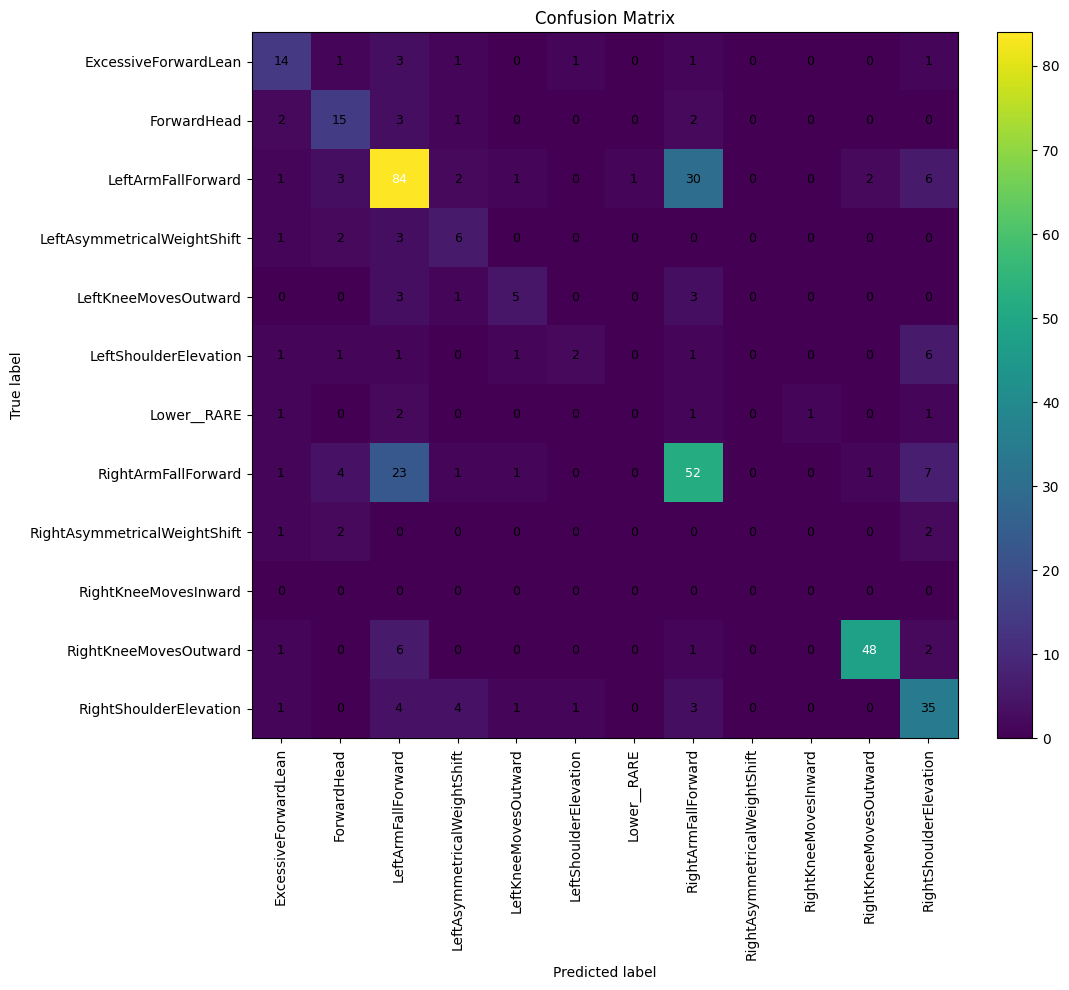

In [45]:
# === Confusion matrix visualization (with numbers) ===
import matplotlib.pyplot as plt
import numpy as np

# Use the same label order you used to build the confusion matrix
class_names = labels_cm  # <-- already defined in your notebook

plt.figure(figsize=(12, 10))
im = plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar(im, fraction=0.046, pad=0.04)

plt.xticks(range(len(class_names)), class_names, rotation=90)
plt.yticks(range(len(class_names)), class_names)

# Put numbers in cells
threshold = cm.max() / 2.0 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        plt.text(
            j, i, f"{val}",
            ha="center", va="center",
            color="white" if val > threshold else "black",
            fontsize=9
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()


## Accuracy metrics

In [37]:
# ============================
# Accuracy metrics (TEST SET)
# ============================
from sklearn.metrics import accuracy_score, balanced_accuracy_score, top_k_accuracy_score, f1_score

# 1) Region model accuracy on test (sanity check)
region_pred_test = region_model.predict(X_test)

print("=== Region model (test) ===")
print("accuracy:", accuracy_score(region_test, region_pred_test))
print("balanced_accuracy:", balanced_accuracy_score(region_test, region_pred_test))
print("macro_f1:", f1_score(region_test, region_pred_test, average="macro"))
print("weighted_f1:", f1_score(region_test, region_pred_test, average="weighted"))
print()

# 2) Final hierarchical model accuracy on test
y_pred_test, proba_test, all_classes = predict_weakest_link_batch(X_test, routing="soft")

# Convert y_test_eval to numpy (needed for top-k)
y_true = y_test_eval.to_numpy()

print("=== Final hierarchical model (test) ===")
print("accuracy:", accuracy_score(y_true, y_pred_test))
print("balanced_accuracy:", balanced_accuracy_score(y_true, y_pred_test))
print("macro_f1:", f1_score(y_true, y_pred_test, average="macro"))
print("weighted_f1:", f1_score(y_true, y_pred_test, average="weighted"))

# Optional: Top-k accuracy (needs probabilities)
# Note: requires sklearn >= 0.24, which you likely have.
for k in [2, 3, 5]:
    try:
        print(f"top_{k}_accuracy:", top_k_accuracy_score(y_true, proba_test, k=k, labels=all_classes))
    except Exception as e:
        print(f"top_{k}_accuracy: (couldn't compute) -> {e}")


=== Region model (test) ===
accuracy: 0.8571428571428571
balanced_accuracy: 0.7427129193306933
macro_f1: 0.757798133259599
weighted_f1: 0.8554329159019479

=== Final hierarchical model (test) ===
accuracy: 0.6214285714285714
balanced_accuracy: 0.4658958104576205
macro_f1: 0.42219679282226563
weighted_f1: 0.6133702025191152
top_2_accuracy: 0.8166666666666667
top_3_accuracy: 0.8761904761904762
top_5_accuracy: 0.9357142857142857


C:\Users\kimwo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [38]:
def parse_european_feature_string(s: str):
    """
    Converts a tab-separated string using comma decimals
    into a Python list of floats.
    """
    # Remove surrounding quotes and whitespace
    s = s.strip().strip('"').strip()
    
    # Split on whitespace (tabs or spaces)
    parts = s.split()
    
    # Replace decimal commas with dots and convert to float
    values = [float(p.replace(",", ".")) for p in parts]
    
    return values


In [39]:
raw_1 = """0,364418938	0,269249163	0,665231946	0,599234816	0,69010043	0,565758011	0,462936394	0,521759923	0,899569584	0,989478718	0,635581062	0,81252989	0,762314682	0,69010043	0,462936394	0,364418938	0,989478718	0,762314682	0,735054998	0,736011478	0,511716882	0,245815399	0,286465806	0,864658058	0,618842659	0,544715447	0,978000956	0,728837877	0,853658537	0,772357724	0,441415591	0,865136298	0,656623625	0,642276423	0,552845528	0,648971784	0,949306552	0,308943089"""

raw_2 = """0,958871353	0,979913917	0,494978479	0,706838833	0,334289813	0,140124342	0,408417025	0,521759923	0,741272119	0,754184601	0,635581062	0,528933525	0,74796748	0,334289813	0,408417025	0,958871353	0,754184601	0,74796748	0,599713056	0,986131038	0,93830703	0,890961263	0,809182209	0,409373505	0,321377331	0,654710665	0,603538977	0,459110473	0,411286466	0,661884266	0,594452415	0,74988044	0,656623625	0,642276423	0,708273553	0,648971784	0,578192253	0,785270206"""

raw_3 = """0,858440937	0,901960784	0,995695839	0,993782879	0,205643233	0,93782879	0,68770923	0,521759923	0,156384505	0,471544715	0,93974175	0,798660928	0,178861789	0,205643233	0,68770923	0,858440937	0,471544715	0,178861789	0,9976088	0,164992826	0,613582018	0,663318986	0,286465806	0,710664754	0,737446198	0,619799139	0,092778575	0,459110473	0,284552846	0,99904352	0,441415591	0,806791009	0,728359637	0,985652798	0,552845528	0,648971784	0,578192253	0,670014347"""

raw_4 = """0,279770445	0,327594452	0,346724055	0,18890483	0,549497848	0,296508847	0,596365375	0,521759923	0,860353898	0,821616451	0,722620756	0,747011	0,890004782	0,549497848	0,596365375	0,279770445	0,821616451	0,890004782	0,471066475	0,37780966	0,512673362	0,707317073	0,684361549	0,870875179	0,980392157	0,544715447	0,730750837	0,581539933	0,854615017	0,420851267	0,649450024	0,670970827	0,838833094	0,642276423	0,692491631	0,817312291	0,922525108	0,308943089"""

raw_5 = """0,358680057	0,641798183	0,495456719	0,883309421	0,300813008	0,901960784	0,230989957	0,548541368	0,307986609	0,424198948	0,870875179	0,401721664	0,442850311	0,300813008	0,230989957	0,358680057	0,424198948	0,442850311	0,890004782	0,464371114	0,445241511	0,286465806	0,621712099	0,602582496	0,607364897	0,666188427	0,4988044	0,459110473	0,397895744	0,449067432	0,523194644	0,846006695	0,656623625	0,642276423	0,703969393	0,648971784	0,578192253	0,594930655"""

example_1 = parse_european_feature_string(raw_1)
example_2 = parse_european_feature_string(raw_2)
example_3 = parse_european_feature_string(raw_3)
example_4 = parse_european_feature_string(raw_4)
example_5 = parse_european_feature_string(raw_5)

print(len(example_1), len(example_2), len(example_3), len(example_4))


38 38 38 38


In [40]:
pred, top = predict_weakest_link(example_1, top_k=5)

print("Predicted WeakestLink:", pred)
for cls, p in top:
    print(f"{cls:30s} {p:.3f}")


Predicted WeakestLink: LeftArmFallForward
LeftArmFallForward             1.000
RightShoulderElevation         0.000
ExcessiveForwardLean           0.000
LeftShoulderElevation          0.000
RightKneeMovesOutward          0.000


In [41]:
pred, top = predict_weakest_link(example_2, top_k=5)

print("Predicted WeakestLink:", pred)
for cls, p in top:
    print(f"{cls:30s} {p:.3f}")


Predicted WeakestLink: RightKneeMovesOutward
RightKneeMovesOutward          0.934
RightArmFallForward            0.045
LeftArmFallForward             0.020
LeftAsymmetricalWeightShift    0.001
RightKneeMovesInward           0.000


In [42]:
pred, top = predict_weakest_link(example_3, top_k=5)

print("Predicted WeakestLink:", pred)
for cls, p in top:
    print(f"{cls:30s} {p:.3f}")


Predicted WeakestLink: RightArmFallForward
RightArmFallForward            0.971
RightKneeMovesOutward          0.028
LeftShoulderElevation          0.001
LeftAsymmetricalWeightShift    0.000
RightKneeMovesInward           0.000


In [43]:
pred, top = predict_weakest_link(example_4, top_k=5)

print("Predicted WeakestLink:", pred)
for cls, p in top:
    print(f"{cls:30s} {p:.3f}")


Predicted WeakestLink: LeftArmFallForward
LeftArmFallForward             1.000
LeftAsymmetricalWeightShift    0.000
RightShoulderElevation         0.000
RightArmFallForward            0.000
ExcessiveForwardLean           0.000


In [44]:
pred, top = predict_weakest_link(example_5, top_k=5)

print("Predicted WeakestLink:", pred)
for cls, p in top:
    print(f"{cls:30s} {p:.3f}")


Predicted WeakestLink: RightArmFallForward
RightArmFallForward            1.000
RightShoulderElevation         0.000
LeftArmFallForward             0.000
LeftShoulderElevation          0.000
RightKneeMovesInward           0.000


## Save models

In [ ]:
joblib.dump({"model": region_model, "feature_cols": feature_cols}, "region_model.pkl")
joblib.dump(upper_bundle, "upper_expert.pkl")
joblib.dump(lower_bundle, "lower_expert.pkl")
joblib.dump(other_bundle, "other_expert.pkl")
print("Saved all models.")
